In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, RocCurveDisplay,
)

In [6]:
# load data
search_dirs = [Path.cwd(), *Path.cwd().parents]
data_path = None
for folder in search_dirs:
    data_dir = folder / "data"
    for name in ["CleanedLifeInsurance.csv", "Cleaned_Life_Insurance.csv"]:
        candidate = data_dir / name
        if candidate.is_file():
            data_path = candidate
            break
    if data_path is not None:
        break

if data_path is None:
    raise FileNotFoundError(
        "Could not find data/CleanedLifeInsurance.csv or "
        "data/Cleaned_Life_Insurance.csv. Run from your project folder."
    )

df = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Dataset shape:", df.shape)

Loaded: /Users/nicolecck/predicting-life-insurance-lapse/data/CleanedLifeInsurance.csv
Dataset shape: (185560, 18)


In [7]:
numeric_features = [
    "ENTRY AGE", "Policy Year", "BENEFIT", "Premium", "SUBSTANDARD RISK"
]
categorical_features = [
    "PAYMENT MODE", "POLICY TYPE 1", "POLICY TYPE 2", "POLICY TYPE 3"
]

X = df[numeric_features + categorical_features]
y = df["is_lapse"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)


In [8]:
def build_model():
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric_features),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("svc", LinearSVC(
            C=1.0,
            class_weight=None,
            loss="squared_hinge",
            dual=False,
            max_iter=3000,
            tol=0.003,
            random_state=42,
        )),
    ])

In [9]:
baseline = build_model()
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['ENTRY AGE','Policy Year','BENEFIT',...,'POLICY TYPE 1','POLICY TYPE 2', 'POLICY TYPE 3']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [10]:
# Tuned model
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(
    estimator=build_model(),
    param_grid={
        "svc__C": [0.01, 0.1, 1.0, 10.0],
        "svc__class_weight": [None, "balanced"],
    },
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
)
search.fit(X_train, y_train)
tuned = search.best_estimator_
print("\nBest tuned parameters:", search.best_params_)
print(f"Best training CV accuracy: {search.best_score_:.4%}")



Best tuned parameters: {'svc__C': 0.1, 'svc__class_weight': None}
Best training CV accuracy: 66.8207%



Baseline LinearSVC
Accuracy: 0.6648
Macro F1: 0.6517
ROC-AUC: 0.7138
              precision    recall  f1-score   support

   Not Lapse       0.69      0.50      0.58     17339
       Lapse       0.65      0.81      0.72     19773

    accuracy                           0.66     37112
   macro avg       0.67      0.65      0.65     37112
weighted avg       0.67      0.66      0.66     37112


Tuned LinearSVC
Accuracy: 0.6649
Macro F1: 0.6518
ROC-AUC: 0.7137
              precision    recall  f1-score   support

   Not Lapse       0.69      0.50      0.58     17339
       Lapse       0.65      0.81      0.72     19773

    accuracy                           0.66     37112
   macro avg       0.67      0.65      0.65     37112
weighted avg       0.67      0.66      0.66     37112



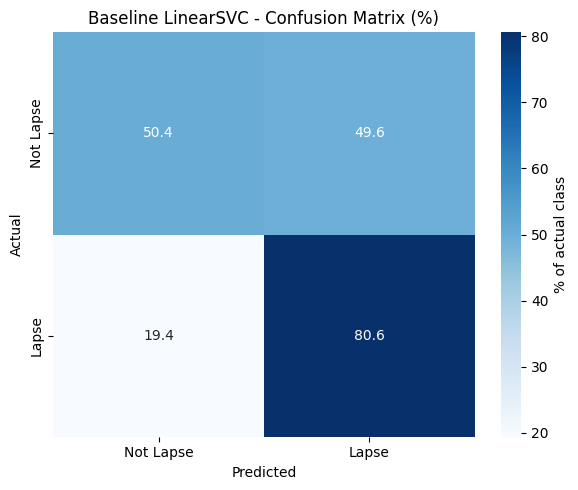

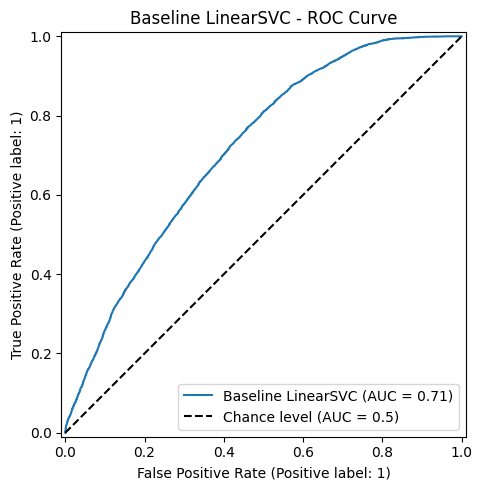

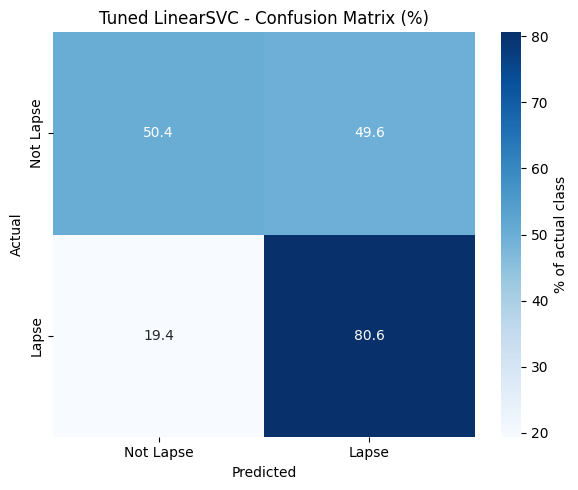

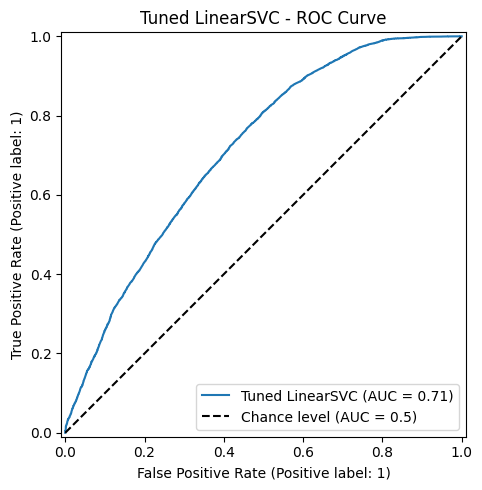

In [11]:
output_dir = data_path.parent.parent / "outputs" / "linearsvc"
output_dir.mkdir(parents=True, exist_ok=True)

results = {}
for label, model, filename in [
    ("Baseline LinearSVC", baseline, "baseline"),
    ("Tuned LinearSVC", tuned, "tuned"),
]:
    y_pred = model.predict(X_test)
    y_score = model.decision_function(X_test)  # NOT predict_proba()
    results[label] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    }
    print(f"\n{label}")
    for metric, value in results[label].items():
        print(f"{metric}: {value:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Not Lapse", "Lapse"]))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm_percent, annot=True, fmt=".1f", cmap="Blues",
        xticklabels=["Not Lapse", "Lapse"],
        yticklabels=["Not Lapse", "Lapse"],
        cbar_kws={"label": "% of actual class"}, ax=ax,
    )
    ax.set(title=f"{label} - Confusion Matrix (%)",
           xlabel="Predicted", ylabel="Actual")
    fig.tight_layout()
    fig.savefig(output_dir / f"{filename}_confusion_matrix.png", dpi=180)

    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_test, y_score, name=label, plot_chance_level=True, ax=ax
    )
    ax.set_title(f"{label} - ROC Curve")
    fig.tight_layout()
    fig.savefig(output_dir / f"{filename}_roc_curve.png", dpi=180)



In [ ]:
comparison = pd.DataFrame(results).T
print("\nBASELINE VS TUNED")
print(comparison.round(4))
print("\nSaved four graphs to:", output_dir)
plt.show()  # Only one plt.show() at the very end.



BASELINE VS TUNED
                    Accuracy  Macro F1  ROC-AUC
Baseline LinearSVC    0.6648    0.6517   0.7138
Tuned LinearSVC       0.6649    0.6518   0.7137

Saved four graphs to: /Users/nicolecck/predicting-life-insurance-lapse/outputs/linearsvc
